# Estado del Plan de Entrega

**Objetivo:** Analizar la calidad del plan de entrega vs. comportamiento real de compra, cuantificar desviaciones, y proponer una estrategia para aplanar la curva de demanda.

In [6]:
from datetime import datetime

import matplotlib.pyplot as mpl
import pandas as pd
import seaborn as sns

sns.set_style("whitegrid")

now = datetime.now().strftime("%d/%m/%Y_%H:%M:%S")

print(f"Last notebook execution: {now}")

Last notebook execution: 16/10/2026_04:14:15


In [7]:
# Load all
tables = {
    "df_plan": pd.read_csv(
        "../data/plan_entrega_clientes_generico.csv",
        parse_dates=["fecha_plan", "fecha_compra_real"],
    ),
}

# Quick profile of each
for name, df in tables.items():
    print(f"\n{'=' * 40}")
    print(f"{name}: {df.shape[0]} rows × {df.shape[1]} cols")
    print(f"  dtypes:\n{df.dtypes}")
    print(f"  nulls: {df.isnull().sum().sum()}")
    print(df.head(3))


df_plan: 739 rows × 8 cols
  dtypes:
cliente_id                        str
centro_distribucion               str
canal_venta                       str
fecha_plan             datetime64[us]
unidades_plan                 float64
fecha_compra_real      datetime64[us]
unidades_reales               float64
fuera_de_plan                   int64
dtype: object
  nulls: 0
    cliente_id centro_distribucion canal_venta fecha_plan  unidades_plan  \
0  CLIENTE_001            CD_NORTE  PORTAL_WEB 2026-01-02         359.88   
1  CLIENTE_001            CD_NORTE  PORTAL_WEB 2026-01-09         219.29   
2  CLIENTE_001            CD_NORTE  PORTAL_WEB 2026-01-16         320.98   

  fecha_compra_real  unidades_reales  fuera_de_plan  
0        2026-01-04           419.58              1  
1        2026-01-09           203.44              0  
2        2026-01-20           379.57              1  


## Datos

| Columna | Tipo | Descripción |
|---------|------|-------------|
| `cliente_id` | str | Identificador único del cliente |
| `centro_distribucion` | str | Centro de distribución (CD_NORTE, CD_SUR, ...) |
| `canal_venta` | str | Canal de venta (PORTAL_WEB, TIENDA, ...) |
| `fecha_plan` | datetime | Fecha planificada de entrega |
| `unidades_plan` | float | Unidades planificadas para esa fecha |
| `fecha_compra_real` | datetime | Fecha real de compra/despacho |
| `unidades_reales` | float | Unidades realmente compradas |
| `fuera_de_plan` | int (0/1) | 1 si la compra se realizó en una fecha distinta a la planificada |

In [8]:
df_plan = tables["df_plan"]

print(df_plan.columns.tolist())
print(f"df shape: {df_plan.shape}")
print(df_plan.head(3))

['cliente_id', 'centro_distribucion', 'canal_venta', 'fecha_plan', 'unidades_plan', 'fecha_compra_real', 'unidades_reales', 'fuera_de_plan']
df shape: (739, 8)
    cliente_id centro_distribucion canal_venta fecha_plan  unidades_plan  \
0  CLIENTE_001            CD_NORTE  PORTAL_WEB 2026-01-02         359.88   
1  CLIENTE_001            CD_NORTE  PORTAL_WEB 2026-01-09         219.29   
2  CLIENTE_001            CD_NORTE  PORTAL_WEB 2026-01-16         320.98   

  fecha_compra_real  unidades_reales  fuera_de_plan  
0        2026-01-04           419.58              1  
1        2026-01-09           203.44              0  
2        2026-01-20           379.57              1  


## Q1: ¿Existe un Bias en el plan de entrega?

¿El plan (unidades y fechas) subestima o sobreestima sistemáticamente el comportamiento real de compra de los clientes?

**Fórmula:**

$$\text{Bias} = \frac{\sum(\text{real} - \text{plan})}{\sum|\text{real}|}$$

- Bias > 0 → el plan **subestima** (los clientes compran más de lo planificado)
- Bias < 0 → el plan **sobreestima** (los clientes compran menos de lo planificado)

### 1.1 Bias global (unidades)

In [9]:
# 1. Overall Bias (units)
total_real = df_plan["unidades_reales"].sum()
total_plan = df_plan["unidades_plan"].sum()
bias_overall = (total_real - total_plan) / total_real
print(f"Overall Bias: {bias_overall:.4f}")
print(f"  Total plan:  {total_plan:,.0f}")
print(f"  Total real:  {total_real:,.0f}")
print(f"  → {'Plan subestima' if bias_overall > 0 else 'Plan sobreestima'}")

Overall Bias: 0.1062
  Total plan:  70,550
  Total real:  78,930
  → Plan subestima


### 1.2 Bias por centro de distribución

In [10]:
# 2. Bias per center
bias_center = (
    df_plan.groupby("centro_distribucion")
    .apply(
        lambda g: (
            (g["unidades_reales"] - g["unidades_plan"]).sum()
            / g["unidades_reales"].sum()
        )
    )
    .rename("Bias")
    .reset_index()
)
print("\n=== Bias per center ===")
print(bias_center.round(4))


=== Bias per center ===
  centro_distribucion    Bias
0           CD_CENTRO  0.0822
1             CD_ESTE  0.1410
2            CD_NORTE  0.1101
3            CD_OESTE  0.0920
4         CD_PACIFICO  0.1284
5              CD_SUR  0.1031


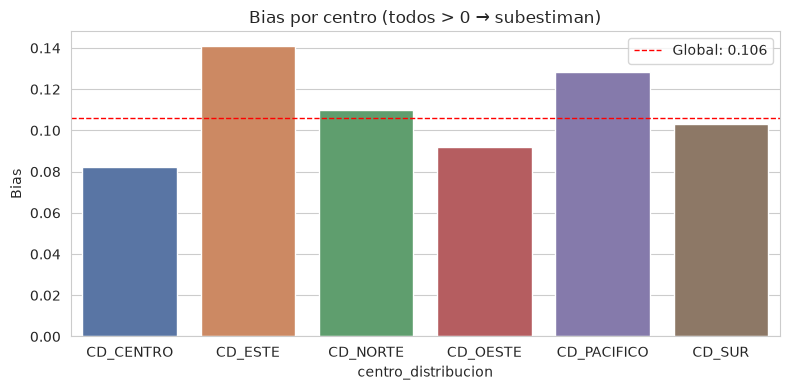

In [11]:
fig, ax = mpl.subplots(figsize=(8, 4))
sns.barplot(
    data=bias_center,
    x="centro_distribucion",
    y="Bias",
    hue="centro_distribucion",
    palette="deep",
    legend=False,
    ax=ax,
)
ax.axhline(y=0, color="black", linewidth=0.5)
ax.axhline(
    y=bias_overall,
    color="red",
    linestyle="--",
    linewidth=1,
    label=f"Global: {bias_overall:.3f}",
)
ax.set_ylabel("Bias")
ax.set_title("Bias por centro (todos > 0 → subestiman)")
ax.legend()
mpl.tight_layout()
mpl.show()

### 1.3 Bias por canal de venta

In [12]:
# 3. Bias per channel
bias_canal = (
    df_plan.groupby("canal_venta")
    .apply(
        lambda g: (
            (g["unidades_reales"] - g["unidades_plan"]).sum()
            / g["unidades_reales"].sum()
        )
    )
    .rename("Bias")
    .reset_index()
)
print("\n=== Bias per channel ===")
print(bias_canal.round(4))


=== Bias per channel ===
           canal_venta    Bias
0     AGENTE_COMERCIAL  0.0993
1  ATENCION_TELEFONICA  0.1083
2           PORTAL_WEB  0.1078


### 1.4 Desviación de fecha (shift)

In [13]:
# 4. Date shift
df_plan["shift_days"] = (df_plan["fecha_compra_real"] - df_plan["fecha_plan"]).dt.days

print("\n=== Date shift ===")
print(f"Mean shift:  {df_plan['shift_days'].mean():.1f} days")
print(f"Median shift: {df_plan['shift_days'].median():.1f} days")
print("  Positive = customer buys LATER than planned (plan is too early)")
print("  Negative = customer buys EARLIER than planned (plan is too late)")


=== Date shift ===
Mean shift:  0.4 days
Median shift: 0.0 days
  Positive = customer buys LATER than planned (plan is too early)
  Negative = customer buys EARLIER than planned (plan is too late)


### 1.5 Tasa off-plan

In [14]:
# 5. Off-plan rate
off_plan_rate = df_plan["fuera_de_plan"].mean()
print(f"\nOff-plan rate: {off_plan_rate:.1%} of purchases are outside the planned date")


Off-plan rate: 17.5% of purchases are outside the planned date


### 1.6 Interpretación

- El plan presenta un Bias global de **+0.106**, lo que indica que **sistemaáticamente subestima** la demanda real (los clientes compran ~10.6% más de lo planificado).
- Por centro: todos subestiman. El más severo es **CD_ESTE** (Bias = +0.141) y el menor **CD_CENTRO** (Bias = +0.082).
- Por canal: los tres canales subestiman de forma uniforme (~0.10), sin diferenciación significativa.
- El shift medio es de **+0.4 días** (mediana = 0) → la fecha planificada es correcta en la mayoría de los casos; la desviación es marginal.
- El **17.5%** de las compras caen fuera de la fecha planificada, a pesar del shift mínimo → el flag `fuera_de_plan` usa criterio estricto de "mismo día".

## Q2: ¿Qué porcentaje de compras se realizan fuera del plan?

Analizar en total, por centro de distribución y por día de la semana planificado.

**Definición:** Off-plan rate = `fuera_de_plan.mean()` → proporción de compras cuya fecha real ≠ fecha planificada.

In [15]:
# 1. Total off-plan rate
total_off_plan = df_plan["fuera_de_plan"].mean()
print("=== Total ===")
print(
    f"Off-plan rate: {total_off_plan:.1%} ({df_plan['fuera_de_plan'].sum()} of {len(df_plan)} purchases)"
)

=== Total ===
Off-plan rate: 17.5% (129 of 739 purchases)


In [16]:
# 2. Per center
off_plan_center = (
    df_plan.groupby("centro_distribucion")["fuera_de_plan"]
    .mean()
    .rename("off_plan_rate")
    .reset_index()
    .sort_values("off_plan_rate", ascending=False)
)
print("\n=== Por centro ===")
print(off_plan_center.round(4))


=== Por centro ===
  centro_distribucion  off_plan_rate
2            CD_NORTE         0.2439
4         CD_PACIFICO         0.2131
1             CD_ESTE         0.1949
5              CD_SUR         0.1885
0           CD_CENTRO         0.1111
3            CD_OESTE         0.1016


In [17]:
# 3. Per day of the week (of the planned date)
df_plan["dia_semana_plan"] = df_plan["fecha_plan"].dt.day_name()
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]

off_plan_dow = (
    df_plan.groupby("dia_semana_plan")["fuera_de_plan"]
    .mean()
    .reindex(day_order)
    .rename("off_plan_rate")
    .reset_index()
)
print("\n=== Por día de la semana (fecha plan) ===")
print(off_plan_dow.round(4))


=== Por día de la semana (fecha plan) ===
  dia_semana_plan  off_plan_rate
0          Monday         0.2212
1         Tuesday         0.1622
2       Wednesday         0.2294
3        Thursday         0.1391
4          Friday         0.1552


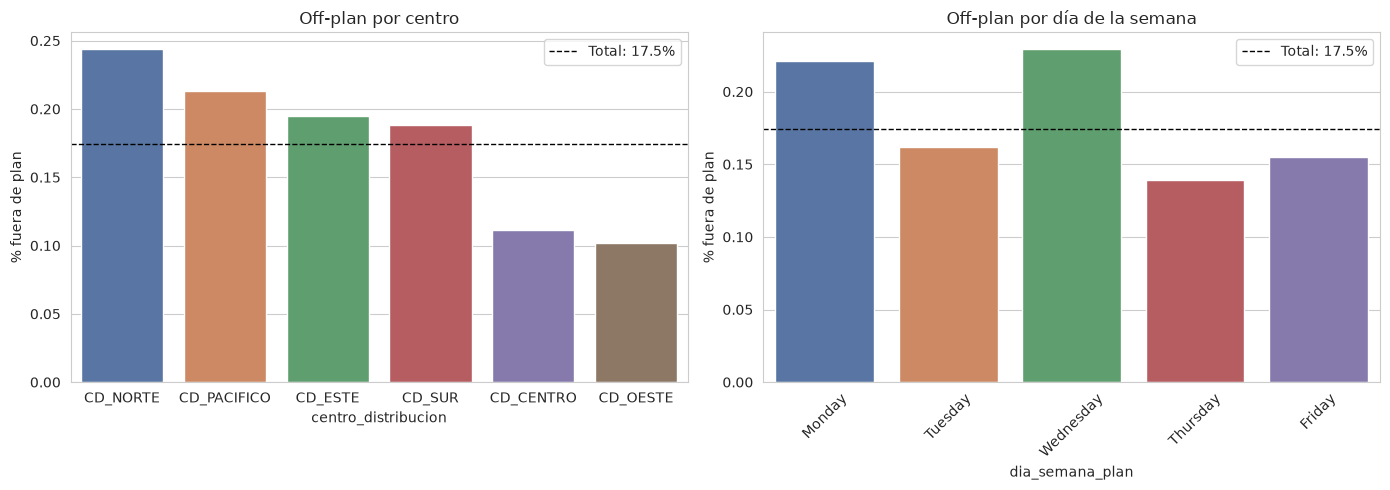

In [18]:
fig, axes = mpl.subplots(1, 2, figsize=(14, 5))

# Per center
sns.barplot(
    data=off_plan_center,
    x="centro_distribucion",
    y="off_plan_rate",
    hue="centro_distribucion",
    palette="deep",
    legend=False,
    ax=axes[0],
)
axes[0].axhline(
    y=total_off_plan,
    color="black",
    linestyle="--",
    linewidth=1,
    label=f"Total: {total_off_plan:.1%}",
)
axes[0].set_title("Off-plan por centro")
axes[0].set_ylabel("% fuera de plan")
axes[0].legend()

# Per day of week
sns.barplot(
    data=off_plan_dow,
    x="dia_semana_plan",
    y="off_plan_rate",
    hue="dia_semana_plan",
    palette="deep",
    order=day_order,
    legend=False,
    ax=axes[1],
)
axes[1].axhline(
    y=total_off_plan,
    color="black",
    linestyle="--",
    linewidth=1,
    label=f"Total: {total_off_plan:.1%}",
)
axes[1].set_title("Off-plan por día de la semana")
axes[1].set_ylabel("% fuera de plan")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()

fig.tight_layout()
mpl.show()

### 2.1 Interpretación

- El off-plan rate global es del **17.5%** (129 de 739 compras).
- El centro con mayor off-plan rate es **CD_NORTE** (24.4%), seguido de **CD_PACIFICO** (21.3%). En contraste, **CD_OESTE** es el más fiable (10.2%).
- Por día: el off-plan es más alto el **miércoles** (22.9%) y el **lunes** (22.1%), y más bajo el **jueves** (13.9%) y **viernes** (15.5%).
- La peor adherencia no coincide con el día de mayor volumen (martes), sino con los días adyacentes → sugiere que la congestión del martes "desborda" hacia días vecinos.
- No hay entregas planificadas en fin de semana.

## Q3: Métricas adicionales para completar el panorama operativo

¿Qué métricas adicionales calcularías para completar el panorama operativo?

| Métrica | Pregunta operativa | Por qué importa |
|---------|-------------------|-----------------|
| **Adhesión por cliente** | *¿Quién* es poco fiable? | Si 20% de clientes generan 80% de off-plan, se pueden segmentar con lógica de planificación distinta. |
| **Distribución del shift** | *¿Cómo* se equivoca el plan? | Shift sistemático (+2 días siempre) → corregir offset. Shift aleatorio (±5 días) → ampliar buffer. |
| **Desviación de volumen** | ¿El *cuánto* es correcto aunque la fecha falle? | Si volumen es preciso pero fecha no → problema de scheduling (fácil de fixear). Si ambos fallan → problema de demanda (requiere re-entrenamiento). |
| **Concentración de desvíos** | ¿El problema es *difuso* o *concentrado*? | Difuso → problema sistémico (modelo/datos). Concentrado → problema local (segmento específico). |
| **Tendencia temporal** | ¿Está *mejorando o empeorando*? | Un snapshot no detecta degradación progresiva por cambios estructurales. |

### 3.1 Adhesión al plan por cliente

In [19]:
# How often does each client buy on the planned date?
adhesion_client = (
    df_plan.groupby("cliente_id")
    .agg(
        total_compras=("fuera_de_plan", "size"),
        off_plan=("fuera_de_plan", "sum"),
    )
    .reset_index()
)
adhesion_client["adhesion_rate"] = (
    1 - adhesion_client["off_plan"] / adhesion_client["total_compras"]
)
adhesion_client = adhesion_client.sort_values("adhesion_rate")

print(f"Clients with <50% adherence: {(adhesion_client['adhesion_rate'] < 0.5).sum()}")
print(adhesion_client.head(10))

Clients with <50% adherence: 3
     cliente_id  total_compras  off_plan  adhesion_rate
11  CLIENTE_012              9         6       0.333333
7   CLIENTE_008              8         5       0.375000
87  CLIENTE_088              8         5       0.375000
8   CLIENTE_009              8         4       0.500000
50  CLIENTE_051              8         4       0.500000
54  CLIENTE_055              8         4       0.500000
83  CLIENTE_084              8         4       0.500000
25  CLIENTE_026              8         4       0.500000
37  CLIENTE_038              9         4       0.555556
79  CLIENTE_080              9         4       0.555556


### 3.2 Distribución del shift de fecha

In [20]:
print(f"Mean shift:   {df_plan['shift_days'].mean():.1f} days")
print(f"Median shift: {df_plan['shift_days'].median():.1f} days")
print(f"Std:          {df_plan['shift_days'].std():.1f} days")
print(f"P90 (late):   {df_plan['shift_days'].quantile(0.9):.1f} days")
print(f"P10 (early):  {df_plan['shift_days'].quantile(0.1):.1f} days")

# Bucketed distribution
bins = [-100, -2.5, -0.5, 0.5, 2.5, 100]
labels = ["≥3 early", "1-2 early", "on time", "1-2 late", "≥3 late"]
df_plan["shift_bucket"] = pd.cut(df_plan["shift_days"], bins=bins, labels=labels)
print("\n=== Shift distribution ===")
print(df_plan["shift_bucket"].value_counts(normalize=True).reindex(labels).round(4))

Mean shift:   0.4 days
Median shift: 0.0 days
Std:          1.6 days
P90 (late):   1.2 days
P10 (early):  0.0 days

=== Shift distribution ===
shift_bucket
≥3 early     0.0108
1-2 early    0.0284
on time      0.8254
1-2 late     0.0514
≥3 late      0.0839
Name: proportion, dtype: float64


/tmp/ipykernel_359311/2387156079.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=shift_dist.index, y=shift_dist.values, palette="deep", ax=ax)


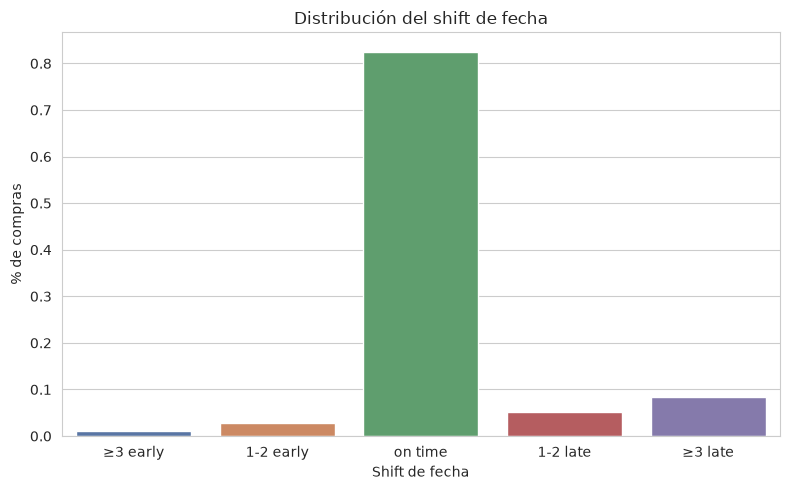

In [21]:
shift_dist = df_plan["shift_bucket"].value_counts(normalize=True).reindex(labels)

fig, ax = mpl.subplots(figsize=(8, 5))
sns.barplot(x=shift_dist.index, y=shift_dist.values, palette="deep", ax=ax)
ax.set_xlabel("Shift de fecha")
ax.set_ylabel("% de compras")
ax.set_title("Distribución del shift de fecha")
mpl.tight_layout()
mpl.show()

### 3.3 Desviación de volumen

In [22]:
df_plan["volume_deviation"] = (
    df_plan["unidades_reales"] - df_plan["unidades_plan"]
) / df_plan["unidades_plan"]

print(f"Mean volume deviation: {df_plan['volume_deviation'].mean():.2%}")
print(f"Median:                {df_plan['volume_deviation'].median():.2%}")
print(f"Std:                   {df_plan['volume_deviation'].std():.2%}")

# Per center
vol_dev_center = (
    df_plan.groupby("centro_distribucion")["volume_deviation"]
    .agg(["mean", "std", "count"])
    .round(4)
)
print("\n=== Volume deviation per center ===")
print(vol_dev_center)

Mean volume deviation: 12.41%
Median:                10.08%
Std:                   19.16%

=== Volume deviation per center ===
                       mean     std  count
centro_distribucion                       
CD_CENTRO            0.0924  0.1833    126
CD_ESTE              0.1629  0.2051    118
CD_NORTE             0.1234  0.2026    123
CD_OESTE             0.1081  0.1748    128
CD_PACIFICO          0.1433  0.1888    122
CD_SUR               0.1179  0.1904    122


### 3.4 Concentración de desvíos (Pareto)

In [23]:
# Which % of clients drive % of off-plan purchases?
off_plan_clients = (
    df_plan[df_plan["fuera_de_plan"] == 1]
    .groupby("cliente_id")
    .size()
    .sort_values(ascending=False)
    .reset_index(name="off_plan_count")
)
total_off = off_plan_clients["off_plan_count"].sum()
off_plan_clients["cum_pct"] = off_plan_clients["off_plan_count"].cumsum() / total_off

n = len(off_plan_clients)
print(
    f"Top 10% of clients drive {off_plan_clients.iloc[int(n * 0.1) - 1]['cum_pct']:.0%} of off-plan purchases"
)
print(
    f"Top 20% of clients drive {off_plan_clients.iloc[int(n * 0.2) - 1]['cum_pct']:.0%} of off-plan purchases"
)

# Concentration by center × channel
concentration = (
    df_plan.groupby(["centro_distribucion", "canal_venta"])["fuera_de_plan"]
    .agg(["sum", "mean", "count"])
    .sort_values("sum", ascending=False)
    .head(10)
)
print("\n=== Top 10 center×channel combos by off-plan count ===")
print(concentration)

Top 10% of clients drive 19% of off-plan purchases
Top 20% of clients drive 36% of off-plan purchases

=== Top 10 center×channel combos by off-plan count ===
                                         sum      mean  count
centro_distribucion canal_venta                              
CD_NORTE            PORTAL_WEB            25  0.297619     84
CD_PACIFICO         PORTAL_WEB            15  0.185185     81
CD_SUR              PORTAL_WEB            14  0.170732     82
CD_ESTE             PORTAL_WEB            14  0.264151     53
CD_CENTRO           PORTAL_WEB             8  0.117647     68
CD_PACIFICO         AGENTE_COMERCIAL       8  0.320000     25
CD_SUR              AGENTE_COMERCIAL       7  0.291667     24
CD_ESTE             ATENCION_TELEFONICA    6  0.187500     32
CD_OESTE            ATENCION_TELEFONICA    6  0.176471     34
CD_CENTRO           AGENTE_COMERCIAL       4  0.097561     41


/tmp/ipykernel_359311/441914319.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


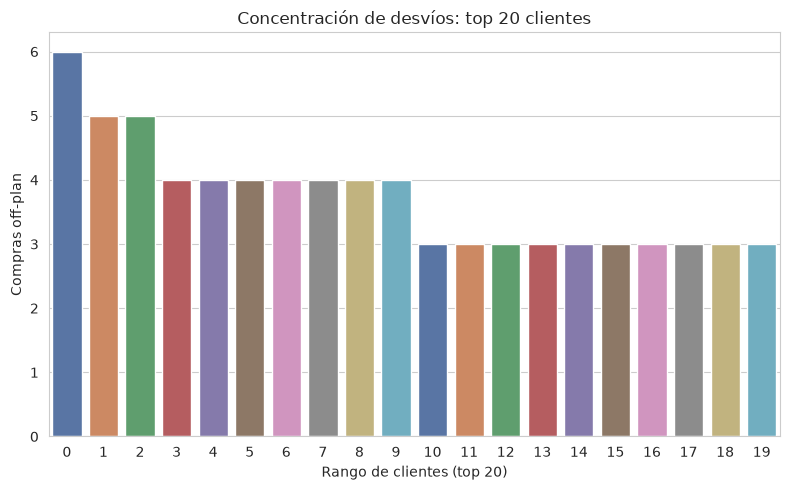

In [24]:
fig, ax = mpl.subplots(figsize=(8, 5))
sns.barplot(
    data=off_plan_clients.head(20),
    x=range(20),
    y="off_plan_count",
    palette="deep",
    ax=ax,
)
ax.set_xlabel("Rango de clientes (top 20)")
ax.set_ylabel("Compras off-plan")
ax.set_title("Concentración de desvíos: top 20 clientes")
mpl.tight_layout()
mpl.show()

### 3.5 Tendencia semanal

In [25]:
df_plan["week"] = df_plan["fecha_plan"].dt.isocalendar().week
weekly = df_plan.groupby("week")["fuera_de_plan"].mean().rename("off_plan_rate")
print("\n=== Weekly off-plan trend ===")
print(weekly.round(4))


=== Weekly off-plan trend ===
week
1    0.2069
2    0.2000
3    0.1444
4    0.1556
5    0.2222
6    0.2444
7    0.1444
8    0.1667
9    0.1000
Name: off_plan_rate, dtype: float64


### 3.6 Interpretación

- El **3%** de los clientes (3 de ~90) tiene <50% de adhesión → candidatos a segmentación.
- El shift es **aleatorio y asimétrico**: mediana = 0 días, std = 1.6 días. El 82.5% es "on time", pero el 13.5% va tarde vs. solo 3.9% temprano → **ampliar buffer hacia adelante** (no corregir offset).
- La desviación de volumen es de **+12.4%** (media) → el plan **no** acierta la cantidad; el problema es **también la demanda** (no solo scheduling). CD_ESTE es el peor (+16.3%).
- El top 10% de clientes genera el **19%** de las compras off-plan → efecto Pareto **débil** (no es 80/20) → tratar como **problema global**, no segmentar.
- Por centro×canal: **CD_NORTE × PORTAL_WEB** concentra el mayor volumen de desvíos (25 off-plan, 29.8% rate) → priorizar este segmento.

## Q4: Estrategia para aplanar la curva de demanda

Sabiendo que los clientes tienen preferencia por comprar en días específicos (pico los martes), ¿qué estrategia propondrías para aplanar la curva?

**Enfoque:** 3 capas progresivas (nudge → incentivo → hard cap). Cada capa se activa solo si la anterior no logra el objetivo.

> **Nota:** El enunciado menciona un pico los martes, pero los datos muestran que el pico real es el **miércoles** (126 unidades vs. 90 el martes). La estrategia se adapta al pico observado en los datos.

### 4.1 Estrategia propuesta

| Capa | Qué hace | Efecto esperado |
|------|----------|-----------------|
| **1. Nudge (comunicación)** | Al momento de la orden, sugerir días alternativos (Lun/Jue) con mensaje: *"Tu pedido llega en el mismo plazo si lo despachas el lunes"* | Mueve ~10-15% sin costo |
| **2. Incentivo diferencial** | Descuento pequeño (2-5%) o prioridad de despacho en días valle (Lun, Jue, Vie) | Mueve ~10-20% adicional |
| **3. Limitación de capacidad (hard cap)** | Tope máximo de unidades por día de despacho (ej: Wednesday cap = 110% del promedio diario) | Fuerza redistribución del excedente |

### 4.2 Implementación

| Paso | Acción | Criterio de activación | Timeline |
|------|--------|----------------------|----------|
| 1 | Nudge en el portal: sugerir Lun/Jue al ordenar para Miércoles | — (siempre activo) | Semana 1-2 |
| 2 | Incentivo: 2-5% descuento o prioridad de despacho en días valle | Si adopción nudge <30% | Semana 3-4 |
| 3 | Hard cap: tope de unidades en Miércoles = 110% del promedio diario | Si peak-to-average sigue >1.3× | Semana 5+ |

**Principio:** minimizar fricción y costo. El cap es la última opción porque genera rechazo si no hay alternativa atractiva.

In [26]:
# 1. Detectar el pico
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]

daily_avg = (
    df_plan.groupby("dia_semana_plan")["unidades_plan"].mean().reindex(day_order)
)
peak_ratio = daily_avg.max() / daily_avg.mean()

print(f"Peak day: {daily_avg.idxmax()} ({daily_avg.max():.0f} units)")
print(f"Average:  {daily_avg.mean():.0f} units")
print(f"Peak-to-average ratio: {peak_ratio:.2f}")
print("\nDaily average units:")
print(daily_avg.round(0))

Peak day: Wednesday (126 units)
Average:  99 units
Peak-to-average ratio: 1.28

Daily average units:
dia_semana_plan
Monday        90.0
Tuesday       90.0
Wednesday    126.0
Thursday      72.0
Friday       114.0
Name: unidades_plan, dtype: float64


### 4.3 KPIs

| KPI | Fórmula | Meta |
|-----|---------|------|
| **Peak-to-average ratio** | `max(daily_units) / mean(daily_units)` | Bajar de 1.28 a <1.20 |
| **Coeficiente de variación diaria** | `std(daily_units) / mean(daily_units)` | Bajar (menor variabilidad) |
| **Off-plan rate** | `fuera_de_plan.mean()` | No debe subir (si sube, el nudge genera fricción) |
| **Adhesión al nuevo plan** | `% pedidos que caen en el día sugerido` | >30% de adopción del nudge |
| **Costo del incentivo** | `descuento_total / revenue_total` | <2% (sostenible) |
| **WAPE post-cambio** | Recalcular con los nuevos datos | No debe degradarse |

In [27]:
# Peak-to-average ratio
before_ratio = daily_avg.max() / daily_avg.mean()

# Coefficient of variation (daily variability)
cv = daily_avg.std() / daily_avg.mean()

# Current off-plan rate
off_plan_rate = df_plan["fuera_de_plan"].mean()

print("=== Baseline KPIs ===")
print(f"Peak-to-average ratio: {before_ratio:.2f}")
print(f"Daily CV:              {cv:.3f}")
print(f"Off-plan rate:         {off_plan_rate:.1%}")

=== Baseline KPIs ===
Peak-to-average ratio: 1.28
Daily CV:              0.217
Off-plan rate:         17.5%


In [28]:
# Define cap: 110% of daily average
cap = daily_avg.mean() * 1.10

# Simulate: for each day, if units > cap, move excess to the next valley day
simulated = daily_avg.copy()
excess = (simulated > cap).astype(float) * (simulated - cap)
simulated[simulated > cap] = cap

# Redistribute excess proportionally to days below cap
valley_mask = simulated < cap
valley_units = simulated[valley_mask]
redistribution = valley_units / valley_units.sum() * excess.sum()
simulated[valley_mask] = simulated[valley_mask] + redistribution

# KPIs after simulation
after_ratio = simulated.max() / simulated.mean()
cv_after = simulated.std() / simulated.mean()

print("=== After cap (110% of avg) ===")
print(f"Peak-to-average ratio: {before_ratio:.2f} → {after_ratio:.2f}")
print(f"Daily CV:              {cv:.3f} → {cv_after:.3f}")
print(f"Improvement:           {(1 - after_ratio / before_ratio):.1%}")

=== After cap (110% of avg) ===
Peak-to-average ratio: 1.28 → 1.10
Daily CV:              0.217 → 0.123
Improvement:           14.0%


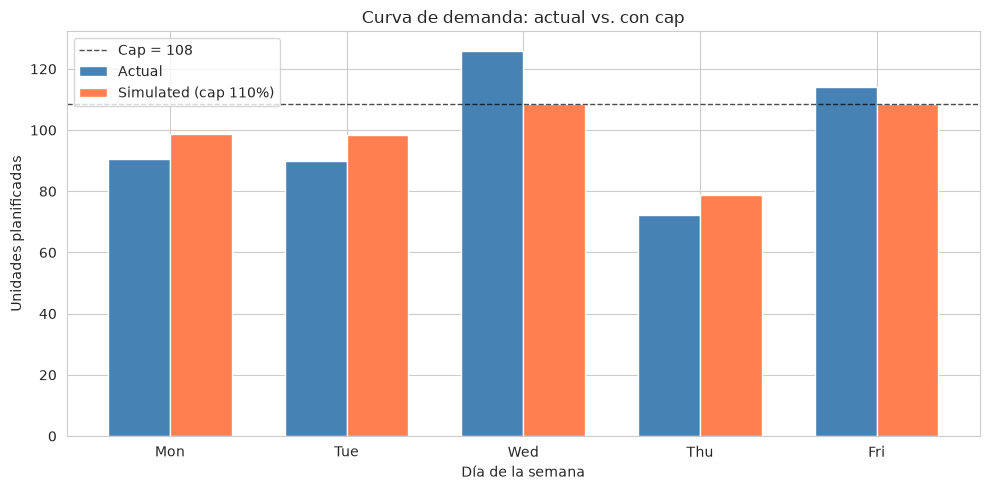

In [29]:
fig, ax = mpl.subplots(figsize=(10, 5))

x = range(len(day_order))
width = 0.35

bars1 = ax.bar(
    [i - width / 2 for i in x],
    daily_avg,
    width,
    label="Actual",
    color="steelblue",
    edgecolor="white",
)
bars2 = ax.bar(
    [i + width / 2 for i in x],
    simulated,
    width,
    label="Simulated (cap 110%)",
    color="coral",
    edgecolor="white",
)

ax.axhline(
    y=cap,
    color="black",
    linestyle="--",
    linewidth=1,
    alpha=0.7,
    label=f"Cap = {cap:.0f}",
)
ax.set_xticks(x)
ax.set_xticklabels([d[:3] for d in day_order])
ax.set_xlabel("Día de la semana")
ax.set_ylabel("Unidades planificadas")
ax.set_title("Curva de demanda: actual vs. con cap")
ax.legend()
mpl.tight_layout()
mpl.show()

### 4.4 Resultado de la simulación

- El cap al 110% del promedio reduce el peak-to-average de **1.28 → 1.10** (mejora del **14.0%**).
- El coeficiente de variación diario baja de **0.217 → 0.123** (−43%).
- Esto es un **techo teórico**: en la práctica, el nudge + incentivo lograrán parte de este efecto sin necesidad del cap.
- El off-plan rate no debe subir como consecuencia → monitorear post-implementación.
- KPI principal a trackear: **peak-to-average ratio** (meta: <1.20×).

In [30]:
kpi_table = pd.DataFrame(
    {
        "KPI": [
            "Peak-to-average ratio",
            "Daily CV",
            "Off-plan rate",
            "Costo incentivo (estimado)",
        ],
        "Antes": [
            f"{before_ratio:.2f}",
            f"{cv:.3f}",
            f"{off_plan_rate:.1%}",
            "—",
        ],
        "Después (simulado)": [
            f"{after_ratio:.2f}",
            f"{cv_after:.3f}",
            "No debe subir",
            "<2% revenue",
        ],
        "Meta": [
            "< 1.20",
            "< 0.15",
            "≤ antes",
            "< 2%",
        ],
    }
)
print(kpi_table.to_string(index=False))

                       KPI Antes Después (simulado)    Meta
     Peak-to-average ratio  1.28               1.10  < 1.20
                  Daily CV 0.217              0.123  < 0.15
             Off-plan rate 17.5%      No debe subir ≤ antes
Costo incentivo (estimado)     —        <2% revenue    < 2%


## Resumen

**Hallazgos clave:**

1. El plan **subestima** la demanda con un Bias global de **+0.106** (los clientes compran ~10.6% más de lo planificado). Todos los centros subestiman; el peor es CD_ESTE (+0.141).
2. El **17.5%** de las compras caen fuera de la fecha planificada. El off-plan es más alto el **miércoles** (22.9%) y el **lunes** (22.1%); CD_NORTE es el centro con peor adherencia (24.4%).
3. El shift de fecha es **aleatorio y asimétrico**: mediana = 0 días, std = 1.6 días. El 82.5% es "on time", pero el 13.5% va tarde vs. solo 3.9% temprano → el plan tiende a ser demasiado optimista en la fecha.
4. La desviación de volumen es de **+12.4%** (media) → el problema es **también de demanda**, no solo de scheduling. El plan subestima la cantidad de forma sistemática.
5. El top 10% de clientes genera el **19%** de las compras off-plan → efecto Pareto débil → el problema es **global**, no concentrado en pocos clientes.

**Recomendación:**

Implementar estrategia de 3 capas progresivas (nudge → incentivo → cap) con KPI principal = **peak-to-average ratio** (baseline: 1.28, meta: <1.20). La simulación del cap al 110% muestra un techo de 1.10 (−14%). Medir a 4 semanas de la primera capa antes de escalar.